**Task 3**

**Step 1: Load the DataSet**

In [1]:
#Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from pathlib import Path

csv_path = Path("data/BankChurners.csv")
if not csv_path.is_file():
    csv_path = Path("../data/BankChurners.csv")

df = pd.read_csv(csv_path)

In [3]:
df.head()

,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,...,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,...,12691.0,777,11914.0,1.335,1144,42,1.625,0.061,0.000093,0.99991
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,...,8256.0,864,7392.0,1.541,1291,33,3.714,0.105,0.000057,0.99994
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,...,3418.0,0,3418.0,2.594,1887,20,2.333,0.000,0.000021,0.99998
3,769911858,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,...,3313.0,2517,796.0,1.405,1171,20,2.333,0.760,0.000134,0.99987
4,709106358,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,...,4716.0,0,4716.0,2.175,816,28,2.500,0.000,0.000022,0.99998


In [4]:
df.shape

(10127, 23)

The BankChurners dataset contains 10,127 customer records and 23 columns containing demographic, relationship, credit, and transaction-related information. The target variable is Attrition_Flag, which identifies existing and attrited customers.

**Basic dataset inspection**

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 23 columns):
 #   Column                                                                                                                              Non-Null Count  Dtype  
---  ------                                                                                                                              --------------  -----  
 0   CLIENTNUM                                                                                                                           10127 non-null  int64  
 1   Attrition_Flag                                                                                                                      10127 non-null  object 
 2   Customer_Age                                                                                                                        10127 non-null  int64  
 3   Gender                                                                           

#Variable Description

1.CLIENTNUM - Unique customer identifier

2.Attrition_Flag - Customer status: existing/attrited

3.Customer_Age - Customer age

4.Gender - Customer gender

5.Dependent_count - Number of dependents

6.Education_Level - Customer's education category

7.Marital_Status - Customer's marital status

8.Income_Category - Customer's income category

9.Card_Category - Credit card category

10.Months_on_book - Duration of customer relationship

11.Total_Relationship_Count - Number of products/relationships held

12.Months_Inactive_12_mon - Number of inactive months in previous 12 months

13.Contacts_Count_12_mon - Number of contacts in previous 12 months

14.Credit_Limit - Credit limit

15.Total_Revolving_Bal - Total revolving balance

16.Avg_Open_To_Buy - Average available credit

17.Total_Amt_Chng_Q4_Q1 - Change in transaction amount from Q1 to Q4

18.Total_Trans_Amt - Total transaction amount

19.Total_Trans_Ct - Total transaction count

20.Total_Ct_Chng_Q4_Q1 - Change in transaction count from Q1 to Q4

21.Avg_Utilization_Ratio - Average credit utilization ratio

Note: The final two Naive Bayes columns are pre-generated classifier-related variables and were not considered meaningful customer characteristics for the descriptive analysis.

In [6]:
df.describe()

,CLIENTNUM,Customer_Age,Dependent_count,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2
count,1.012700e+04,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000
mean,7.391776e+08,46.325960,2.346203,35.928409,3.812580,2.341167,2.455317,8631.953698,1162.814061,7469.139637,0.759941,4404.086304,64.858695,0.712222,0.274894,0.159997,0.840003
std,3.690378e+07,8.016814,1.298908,7.986416,1.554408,1.010622,1.106225,9088.776650,814.987335,9090.685324,0.219207,3397.129254,23.472570,0.238086,0.275691,0.365301,0.365301
min,7.080821e+08,26.000000,0.000000,13.000000,1.000000,0.000000,0.000000,1438.300000,0.000000,3.000000,0.000000,510.000000,10.000000,0.000000,0.000000,0.000008,0.000420
25%,7.130368e+08,41.000000,1.000000,31.000000,3.000000,2.000000,2.000000,2555.000000,359.000000,1324.500000,0.631000,2155.500000,45.000000,0.582000,0.023000,0.000099,0.999660
50%,7.179264e+08,46.000000,2.000000,36.000000,4.000000,2.000000,2.000000,4549.000000,1276.000000,3474.000000,0.736000,3899.000000,67.000000,0.702000,0.176000,0.000181,0.999820
75%,7.731435e+08,52.000000,3.000000,40.000000,5.000000,3.000000,3.000000,11067.500000,1784.000000,9859.000000,0.859000,4741.000000,81.000000,0.818000,0.503000,0.000337,0.999900
max,8.283431e+08,73.000000,5.000000,56.000000,6.000000,6.000000,6.000000,34516.000000,2517.000000,34516.000000,3.397000,18484.000000,139.000000,3.714000,0.999000,0.999580,0.999990


CLIENTNUM is a unique customer identifier and was not treated as a meaningful analytical variable.

In [7]:
#Categorical variables
df.describe(include="object")

,Attrition_Flag,Gender,Education_Level,Marital_Status,Income_Category,Card_Category
count,10127,10127,10127,10127,10127,10127
unique,2,2,7,4,6,4
top,Existing Customer,F,Graduate,Married,Less than $40K,Blue
freq,8500,5358,3128,4687,3561,9436


**Step 2: Data Quality**

In [8]:
#Missing values
df.isnull().sum()

CLIENTNUM                                                                                                                             0
Attrition_Flag                                                                                                                        0
Customer_Age                                                                                                                          0
Gender                                                                                                                                0
Dependent_count                                                                                                                       0
Education_Level                                                                                                                       0
Marital_Status                                                                                                                        0
Income_Category                                 

In [9]:
#Total missing values
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


In [10]:
#Duplicate values
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [11]:
#Inspect category frequencies and identify "Unknown" values
categorical_cols = df.select_dtypes(include="object").columns

for col in categorical_cols:
    print(f"\n{col}")
    print(df[col].value_counts())


Attrition_Flag
Attrition_Flag
Existing Customer    8500
Attrited Customer    1627
Name: count, dtype: int64

Gender
Gender
F    5358
M    4769
Name: count, dtype: int64

Education_Level
Education_Level
Graduate         3128
High School      2013
Unknown          1519
Uneducated       1487
College          1013
Post-Graduate     516
Doctorate         451
Name: count, dtype: int64

Marital_Status
Marital_Status
Married     4687
Single      3943
Unknown      749
Divorced     748
Name: count, dtype: int64

Income_Category
Income_Category
Less than $40K    3561
$40K - $60K       1790
$80K - $120K      1535
$60K - $80K       1402
Unknown           1112
$120K +            727
Name: count, dtype: int64

Card_Category
Card_Category
Blue        9436
Silver       555
Gold         116
Platinum      20
Name: count, dtype: int64


In [12]:
# Count Unknown values in categorical variables

unknown_counts = {}

for col in categorical_cols:
    unknown_counts[col] = (df[col] == "Unknown").sum()

pd.Series(unknown_counts, name="Unknown_Count")

Attrition_Flag        0
Gender                0
Education_Level    1519
Marital_Status      749
Income_Category    1112
Card_Category         0
Name: Unknown_Count, dtype: int64

Data Quality Interpretation

No conventional missing (NaN) values or duplicate records were identified in
the dataset. However, "Unknown" categories were found in Education_Level
(1,519 records), Marital_Status (749 records), and Income_Category
(1,112 records).

These records were retained because an unknown value in one demographic
variable does not necessarily make the remaining customer information invalid.
Removing these records could result in unnecessary loss of useful customer data.

**Step 3: Outlier Detection**

Step 3.1: Detect outliers using IQR method

In [13]:
# Select meaningful numerical variables for outlier analysis

numeric_cols = [
    'Customer_Age',
    'Dependent_count',
    'Months_on_book',
    'Total_Relationship_Count',
    'Months_Inactive_12_mon',
    'Contacts_Count_12_mon',
    'Credit_Limit',
    'Total_Revolving_Bal',
    'Avg_Open_To_Buy',
    'Total_Amt_Chng_Q4_Q1',
    'Total_Trans_Amt',
    'Total_Trans_Ct',
    'Total_Ct_Chng_Q4_Q1',
    'Avg_Utilization_Ratio'
]

In [14]:
# Detect outliers using the IQR method

outlier_counts = {}

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_counts[col] = (
        (df[col] < lower_bound) | (df[col] > upper_bound)
    ).sum()

pd.Series(outlier_counts, name="Outlier_Count")

Customer_Age                  2
Dependent_count               0
Months_on_book              386
Total_Relationship_Count      0
Months_Inactive_12_mon      331
Contacts_Count_12_mon       629
Credit_Limit                984
Total_Revolving_Bal           0
Avg_Open_To_Buy             963
Total_Amt_Chng_Q4_Q1        396
Total_Trans_Amt             896
Total_Trans_Ct                2
Total_Ct_Chng_Q4_Q1         394
Avg_Utilization_Ratio         0
Name: Outlier_Count, dtype: int64

Step 3.2: Visualize potential outliers using boxplots

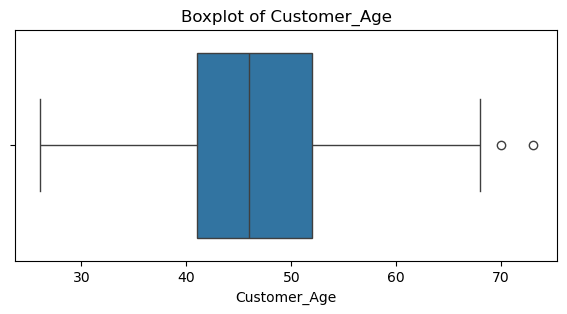

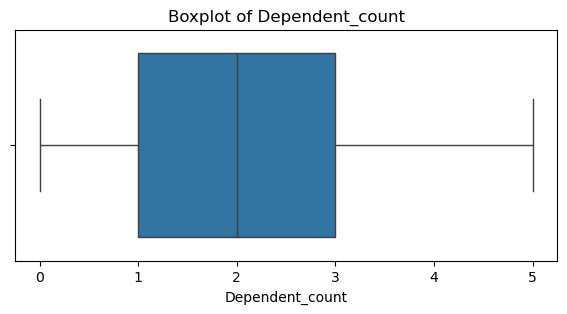

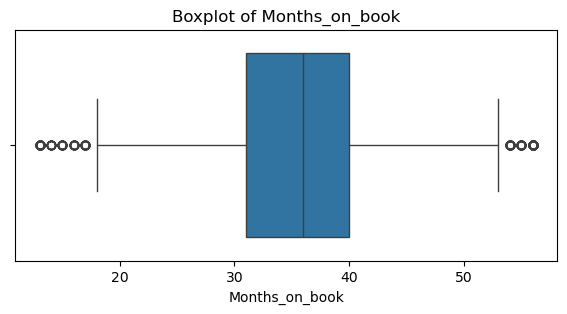

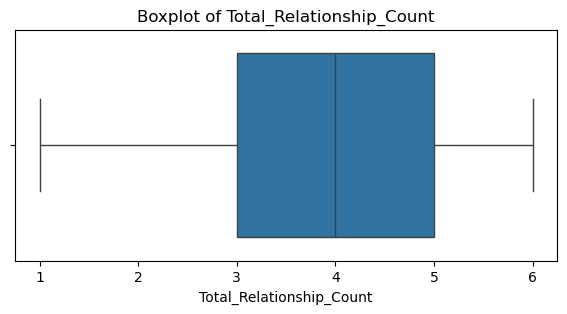

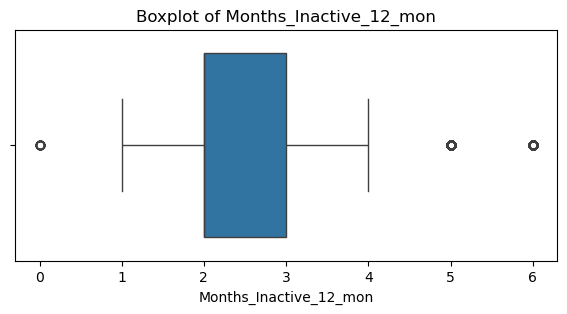

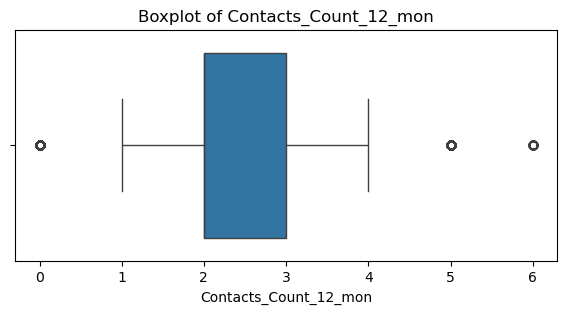

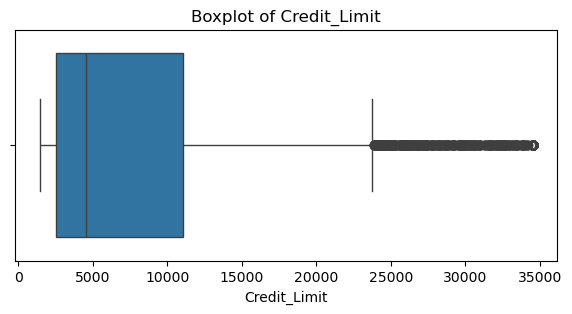

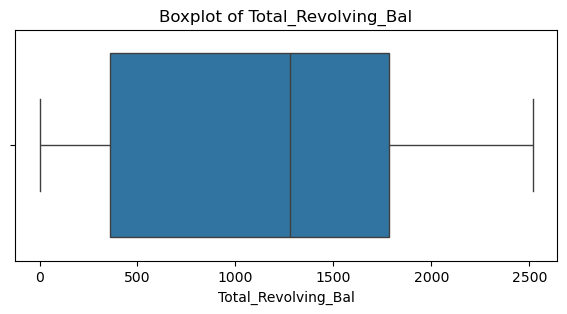

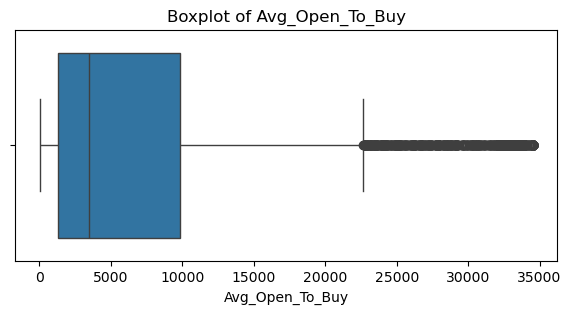

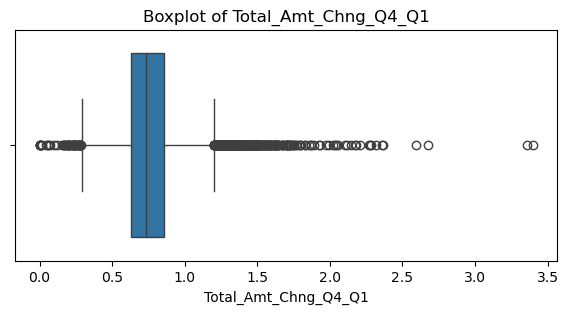

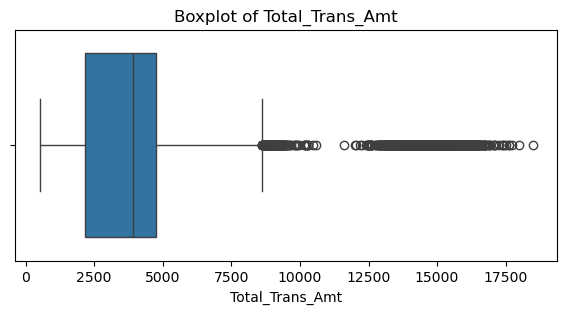

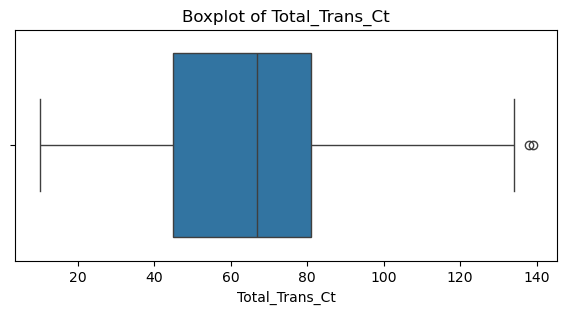

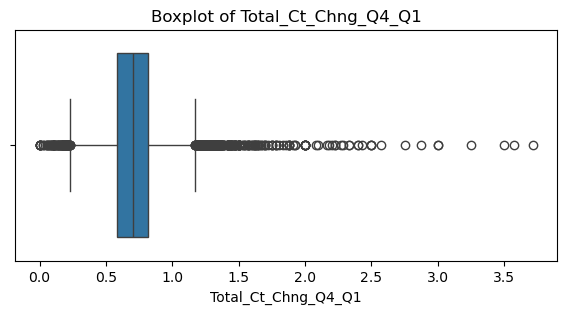

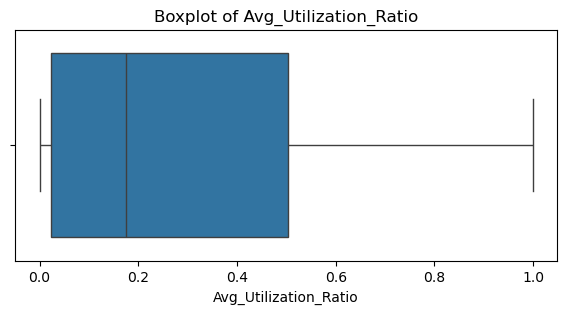

In [15]:
# Visualize numerical variables using boxplots

for col in numeric_cols:
    plt.figure(figsize=(7, 3))
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot of {col}')
    plt.xlabel(col)
    plt.show()

Step 3.3: Outlier Interpretation

The IQR method identified potential outliers in several numerical variables, including Customer_Age, Months_on_book, Months_Inactive_12_mon, Contacts_Count_12_mon, Credit_Limit, Avg_Open_To_Buy, Total_Amt_Chng_Q4_Q1, Total_Trans_Amt, Total_Trans_Ct, and Total_Ct_Chng_Q4_Q1. The boxplots were used to visually examine these extreme observations. These values were retained for the descriptive analysis because extreme values in financial and customer behavioural variables may represent genuine customer characteristics rather than data errors. Therefore, automatically removing them could result in the loss of meaningful information.

**Step 4: Descriptive Analysis**


Step 4.1: Customer Attrition Distribution

In [16]:
#Target Variable
df["Attrition_Flag"].value_counts()

Attrition_Flag
Existing Customer    8500
Attrited Customer    1627
Name: count, dtype: int64

In [17]:
# Customer attrition percentages
df["Attrition_Flag"].value_counts(normalize=True).mul(100).round(2)

Attrition_Flag
Existing Customer    83.93
Attrited Customer    16.07
Name: proportion, dtype: float64

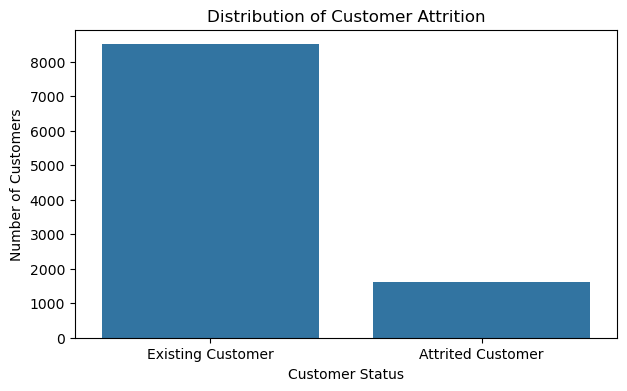

In [18]:
plt.figure(figsize=(7, 4))

sns.countplot(
    data=df,
    x="Attrition_Flag"
)

plt.title("Distribution of Customer Attrition")
plt.xlabel("Customer Status")
plt.ylabel("Number of Customers")
plt.show()

The dataset contains 8,500 existing customers and 1,627 attrited customers. Approximately 16.07% of customers are attrited, compared with 83.93% existing customers. This indicates an imbalanced distribution of the target variable, with attrited customers forming the minority group.

Step 4.2: Numerical Variables by Customer Attrition Status

In [19]:
# Compare key numerical variables by attrition status

comparison_cols = [
    'Customer_Age',
    'Total_Relationship_Count',
    'Months_Inactive_12_mon',
    'Contacts_Count_12_mon',
    'Credit_Limit',
    'Total_Revolving_Bal',
    'Total_Trans_Amt',
    'Total_Trans_Ct',
    'Avg_Utilization_Ratio'
]

attrition_summary = df.groupby('Attrition_Flag')[comparison_cols].mean().round(2)

attrition_summary

,Customer_Age,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Total_Trans_Amt,Total_Trans_Ct,Avg_Utilization_Ratio
Attrition_Flag,,,,,,,,,
Attrited Customer,46.66,3.28,2.69,2.97,8136.04,672.82,3095.03,44.93,0.16
Existing Customer,46.26,3.91,2.27,2.36,8726.88,1256.60,4654.66,68.67,0.30


Numerical Comparison: Attrited customers show lower average transaction counts (44.93 vs. 68.67), transaction amounts (3,095.03 vs. 4,654.66), revolving balances (672.82 vs. 1,256.60), and relationship counts (3.28 vs. 3.91) than existing customers. They also show higher average inactivity (2.69 vs. 2.27 months) and contact counts (2.97 vs. 2.36). These are descriptive differences and do not by themselves establish statistical significance.

Step 4.3: Visualize Key Differences

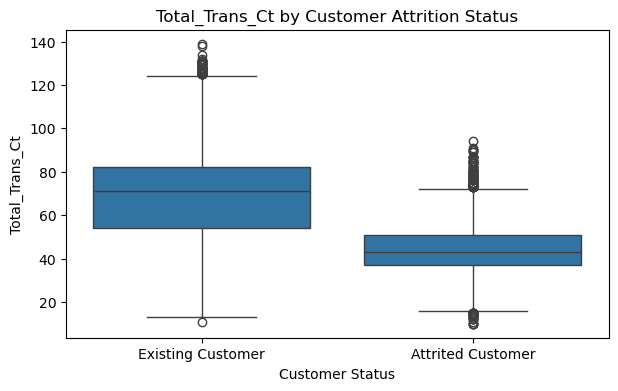

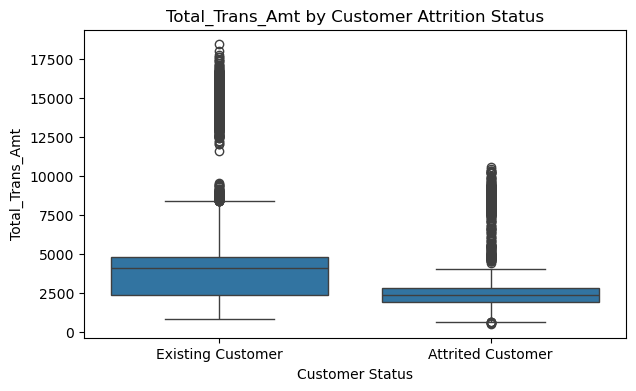

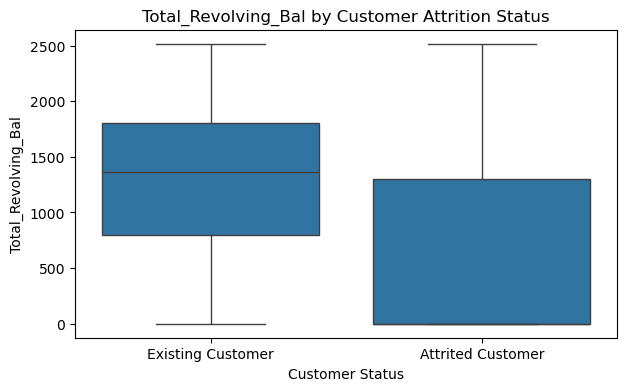

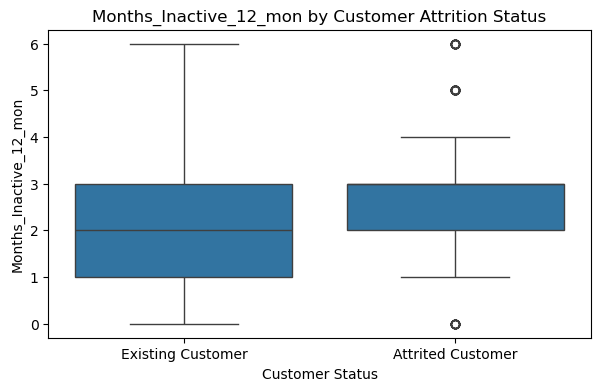

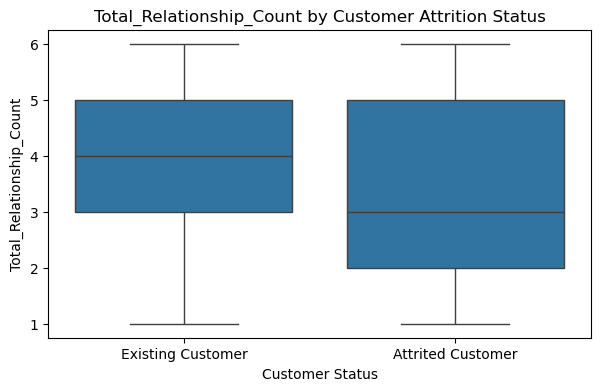

In [20]:
# Visualize key numerical differences by attrition status

key_variables = [
    'Total_Trans_Ct',
    'Total_Trans_Amt',
    'Total_Revolving_Bal',
    'Months_Inactive_12_mon',
    'Total_Relationship_Count'
]

for col in key_variables:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=df, x='Attrition_Flag', y=col)
    plt.title(f'{col} by Customer Attrition Status')
    plt.xlabel('Customer Status')
    plt.ylabel(col)
    plt.show()

Attrited customers exhibit lower transaction activity, lower revolving balances, fewer relationships with the bank, and higher inactivity than existing customers. These patterns suggest potential associations with customer attrition, but inferential analysis is required to determine whether the observed differences are statistically significant.

Step 4.4: Categorical Variables vs Attrition

In [21]:
# Churn percentages within each categorical variable

categorical_features = [
    'Gender',
    'Education_Level',
    'Marital_Status',
    'Income_Category',
    'Card_Category'
]

for col in categorical_features:
    print(f"\n{col}")

    churn_percentage = pd.crosstab(
        df[col],
        df['Attrition_Flag'],
        normalize='index'
    ) * 100

    print(churn_percentage.round(2))


Gender
Attrition_Flag  Attrited Customer  Existing Customer
Gender                                              
F                           17.36              82.64
M                           14.62              85.38

Education_Level
Attrition_Flag   Attrited Customer  Existing Customer
Education_Level                                      
College                      15.20              84.80
Doctorate                    21.06              78.94
Graduate                     15.57              84.43
High School                  15.20              84.80
Post-Graduate                17.83              82.17
Uneducated                   15.94              84.06
Unknown                      16.85              83.15

Marital_Status
Attrition_Flag  Attrited Customer  Existing Customer
Marital_Status                                      
Divorced                    16.18              83.82
Married                     15.13              84.87
Single                      16.94              83

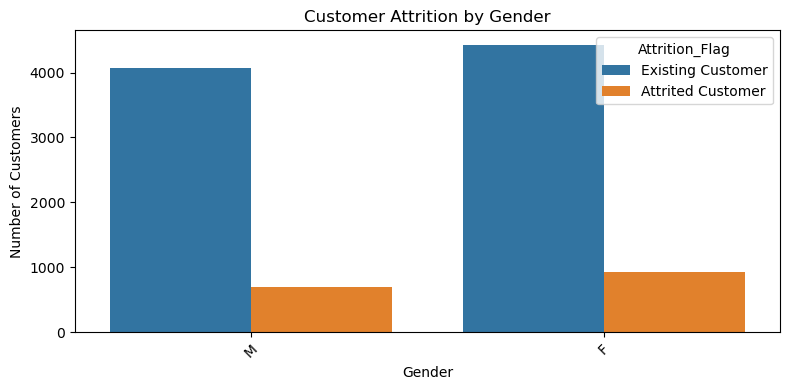

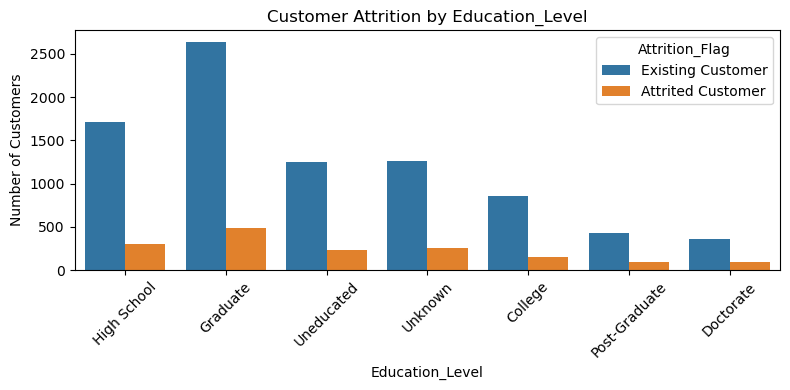

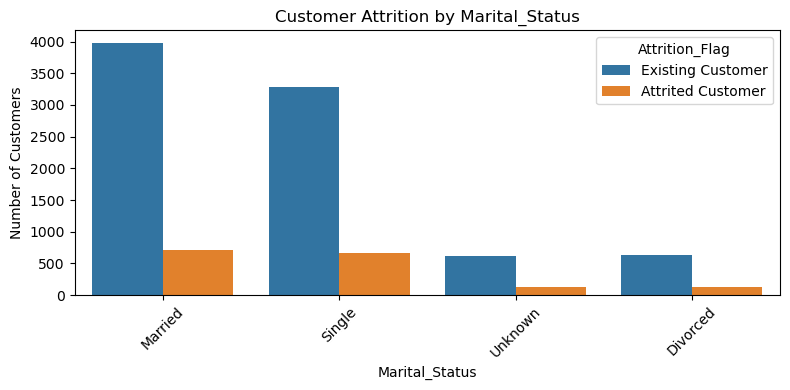

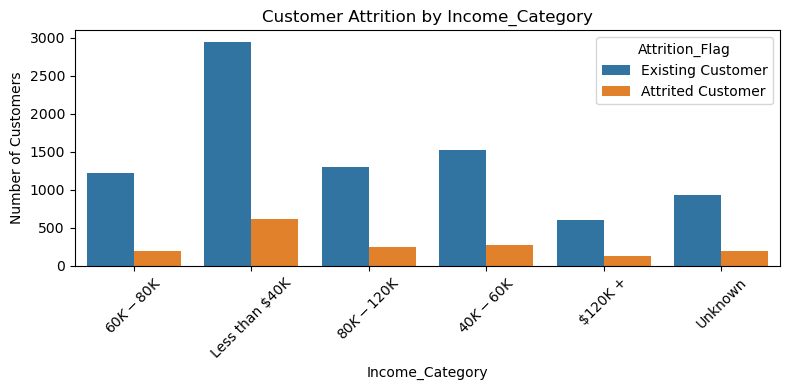

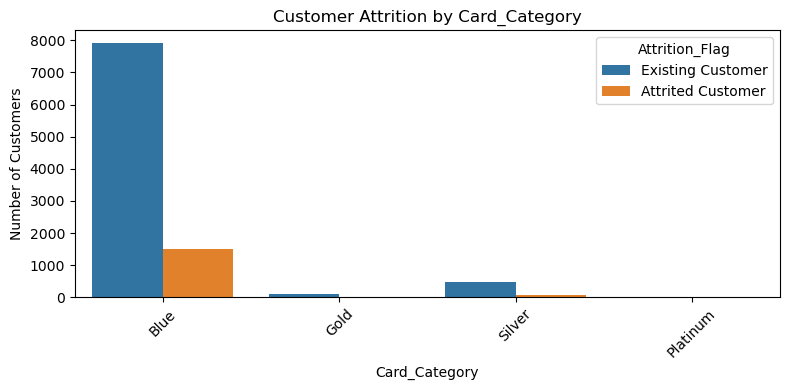

In [22]:
# Visualize categorical variables by attrition status

for col in categorical_features:
    plt.figure(figsize=(8, 4))

    sns.countplot(
        data=df,
        x=col,
        hue='Attrition_Flag'
    )

    plt.title(f'Customer Attrition by {col}')
    plt.xlabel(col)
    plt.ylabel('Number of Customers')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

Categorical Comparison: Descriptive differences in attrition rates are observed across several customer categories. Female customers show a higher attrition rate (17.36%) than male customers (14.62%). Attrition also varies across education, income, marital-status, and card categories. For example, the observed attrition rate is 25.00% among Platinum card customers. However, category sizes differ substantially, so these percentages should be interpreted cautiously and inferential analysis is required before concluding that these characteristics are significantly associated with attrition.

Step 4.5: Correlation Analysis

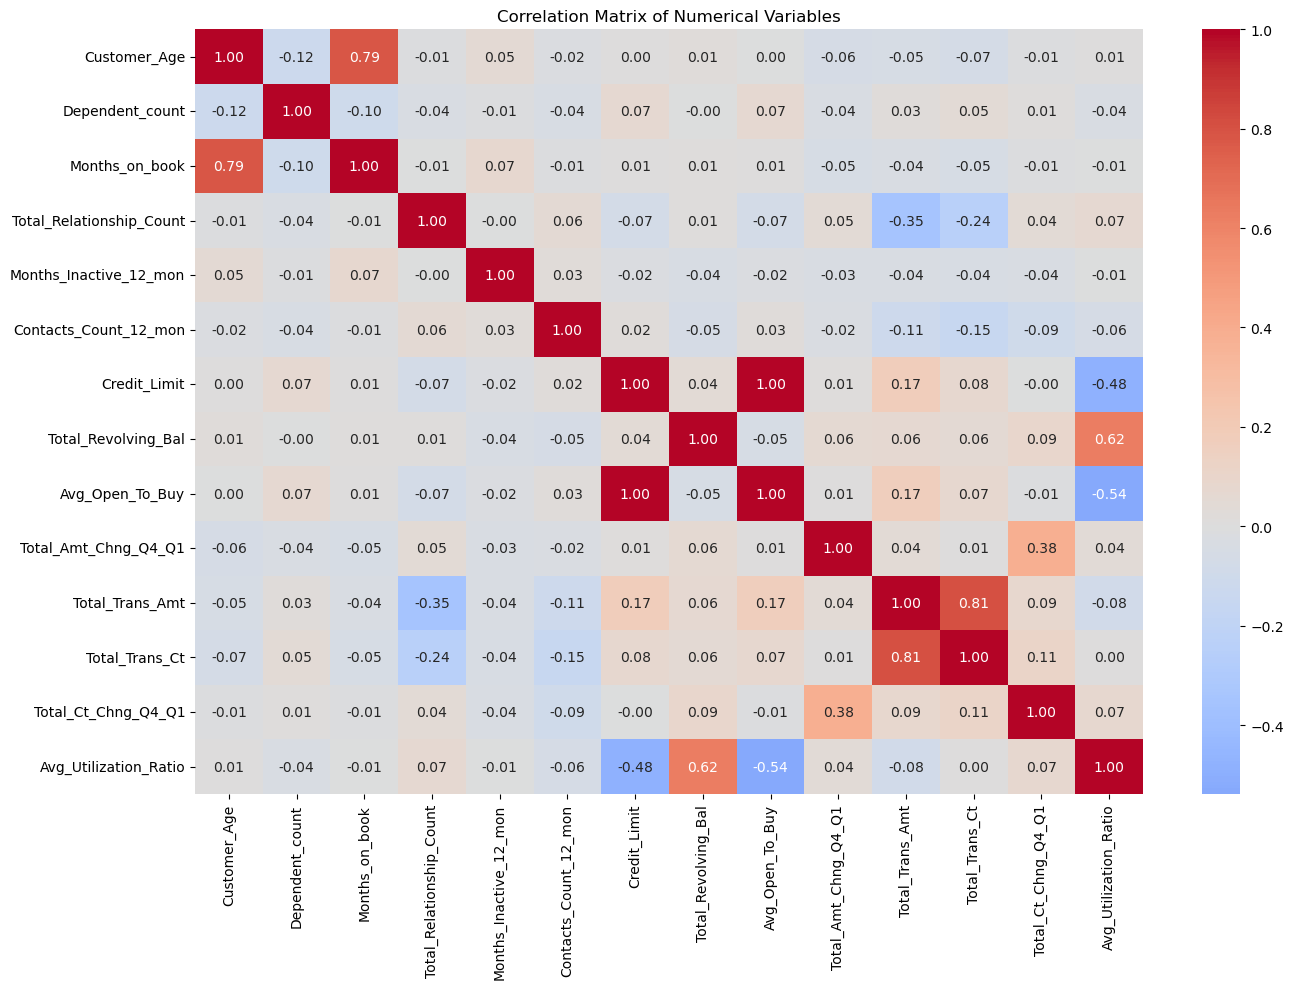

In [23]:
# Correlation matrix for numerical variables
correlation_matrix = df[numeric_cols].corr()

# Correlation heatmap
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix of Numerical Variables")
plt.tight_layout()
plt.show()

Correlation Analysis: The correlation matrix indicates several notable relationships among the numerical variables. Total transaction amount and total transaction count show a strong positive correlation (r = 0.81), indicating that customers who make more transactions generally have higher transaction amounts. Customer age and months on book are also strongly positively correlated (r = 0.79). Credit limit and average open-to-buy show an extremely strong positive relationship (r ≈ 1.00). These correlations describe associations between variables and do not imply causation.

**Step 5: Initial Business Insights**

Initial Business Insights

1.
Customer attrition is a notable retention concern: Out of 10,127 customers, 1,627 (16.07%) are attrited customers, while 83.93% remain existing customers.

2.
Lower transaction activity is associated with attrition: Attrited customers recorded a lower average transaction count (44.93) than existing customers (68.67). Their average total transaction amount was also lower (3,095.03 compared with 4,654.66).

3.
Customer inactivity may be an important warning indicator: Attrited customers were inactive for an average of 2.69 months during the previous 12 months, compared with 2.27 months among existing customers.

4.
Attrited customers tend to have fewer relationships with the bank: The average total relationship count was 3.28 for attrited customers compared with 3.91 for existing customers, suggesting that customers with fewer banking relationships may require greater retention attention.

5.
Credit usage behaviour differs between the two groups: Attrited customers had a lower average revolving balance (672.82) than existing customers (1,256.60) and a lower average utilization ratio (0.16 compared with 0.30).

6.
Customer contact patterns also differ: Attrited customers had a higher average number of contacts during the previous 12 months (2.97) than existing customers (2.36), which may help identify customers requiring retention attention.

Overall Business Implication: The descriptive analysis indicates that lower transaction activity, greater inactivity, fewer banking relationships, lower credit utilization, and higher contact frequency are associated with customer attrition. These characteristics may help the bank identify potentially vulnerable customer groups and guide retention strategies. However, these findings are descriptive associations and should be validated through inferential statistical analysis and predictive modelling before making stronger conclusions.